In [ ]:
!pip install tensorflow opencv-python-headless pandas scikit-learn matplotlib seaborn -q
import os
import cv2
import numpy as np
import pandas as pd
import urllib.request
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import joblib

import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

images_folder = "/content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces"
csv_file = "/content/drive/MyDrive/Colab Notebooks/Dataset/data.csv"

df = pd.read_csv(csv_file)
df["ID"] = df["ID"].astype(str)

print(df.head())
print(os.listdir(images_folder))

Mounted at /content/drive
      Role    ID          Name  Gender Faculty                  Course
0    Staff  E001  Henry Cavill    Male    FAFB                     NaN
1  Student  S001   Lisa Kudrow  Female    FAFB   Diploma in Accounting
2  Student  S002    Alia Bhatt  Female    FOAS  Bachelor in Bioscience
3    Staff  E002    Tom Cruise    Male    FOCS                     NaN
4    Staff  E003     Zac Efron    Male    FAFB                     NaN
['E001', 'S001', 'S002', 'E002', 'E003', 'S003', 'S004', 'E004', 'E005', 'S005', 'S006', 'S007', 'S008', 'S009', 'S010', 'S011', 'S012', 'E006', 'S013', 'S014', 'E007', 'S015', 'S016', 'E008', 'E009', 'S017', 'S018', 'S019', 'E010', 'S020', 'S022', 'S023', 'S024', 'S025', 'S021']


In [ ]:
# Detect faces and build labeled dataset
IMG_SIZE = 100

YUNET_MODEL_URL = "https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx"
YUNET_MODEL_PATH = "face_detection_yunet_2023mar.onnx"

YUNET_SCORE_THRESHOLD = 0.7   # min confidence to keep a detection
YUNET_NMS_THRESHOLD = 0.3     # non-max suppression IoU threshold
YUNET_TOP_K = 5000            # max detections kept before NMS
YUNET_MIN_FACE_SIZE = 60      # matches the old Haar minSize=(60, 60)

urllib.request.urlretrieve(YUNET_MODEL_URL,YUNET_MODEL_PATH)

face_detector = cv2.FaceDetectorYN.create(
    YUNET_MODEL_PATH, "", (320, 320),
    YUNET_SCORE_THRESHOLD, YUNET_NMS_THRESHOLD, YUNET_TOP_K,
)

def detect_faces_yunet(image):
    """
    Runs YuNet on a BGR image and returns a list of (x, y, w, h) int boxes,
    the same shape CascadeClassifier.detectMultiScale used to return -- so
    downstream code (largest-face selection, cropping) is unchanged.
    """
    h, w = image.shape[:2]
    face_detector.setInputSize((w, h))
    _, faces = face_detector.detect(image)
    boxes = []
    if faces is not None:
        for f in faces:
            x, y, fw, fh = f[:4]
            x, y, fw, fh = int(round(x)), int(round(y)), int(round(fw)), int(round(fh))
            if fw >= YUNET_MIN_FACE_SIZE and fh >= YUNET_MIN_FACE_SIZE:
                boxes.append((max(x, 0), max(y, 0), fw, fh))
    return boxes

def detect_and_crop_face(image):
    """
    Returns the largest detected face crop (RGB, IMG_SIZE x IMG_SIZE), or None.
    """
    faces = detect_faces_yunet(image)
    if len(faces) == 0:
        return None
    x, y, w, h = max(faces, key=lambda f: f[2] * f[3])

    # Crop the raw RGB/BGR image instead of grayscale
    face = image[y:y+h, x:x+w]
    face = cv2.resize(face, (IMG_SIZE, IMG_SIZE))
    # Convert BGR to RGB for standard neural network input compatibility
    face = cv2.cvtColor(face, cv2.COLOR_BGR2RGB)
    return face

X, y = [], []
skipped = 0

for person_id in sorted(os.listdir(images_folder)):
    person_dir = os.path.join(images_folder, person_id)
    if not os.path.isdir(person_dir):
        continue
    for filename in os.listdir(person_dir):
        if not filename.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            continue
        filepath = os.path.join(person_dir, filename)
        image = cv2.imread(filepath)

        if image is None:
            print(f"[Unreadable] {filepath}")
            skipped += 1
            continue

        face = detect_and_crop_face(image)

        if face is None:
            print(f"[No face detected] {filepath}")
            skipped += 1
            continue
        X.append(face)
        y.append(person_id)

X = np.array(X, dtype=np.float32) / 255.0
y = np.array(y)

print("Total usable images:", len(X))
print("Skipped (no face found / unreadable):", skipped)
print("Number of people (classes):", len(np.unique(y)))

[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_018.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_045.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_033.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_068.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_027.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_029.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_036.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_090.jpg
[No face detected] /content/drive/MyDrive/Colab Notebooks/Dataset/stored-faces/E001/Henry_Cavill_008.jpg
[No face detected] /content/drive/MyDrive/Colab Noteboo

In [ ]:
# =========== Face Mask Detector (pretrained) ===========
# Pretrained MobileNetV2-based mask / no-mask classifier
# (Chandrika Deb, "Face-Mask-Detection", MIT License)
import urllib.request
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.layers import AveragePooling2D, Dropout, Flatten, Dense, Input
from tensorflow.keras.models import Model

MASK_MODEL_PATH = "mask_detector.h5"
MASK_MODEL_URL = "https://raw.githubusercontent.com/chandrikadeb7/Face-Mask-Detection/master/mask_detector.model"
MASK_IMG_SIZE = 224  # input size expected by this pretrained model

if not os.path.exists(MASK_MODEL_PATH):
    urllib.request.urlretrieve(MASK_MODEL_URL, MASK_MODEL_PATH)

_base = MobileNetV2(weights=None, include_top=False, input_tensor=Input(shape=(MASK_IMG_SIZE, MASK_IMG_SIZE, 3)))
_head = _base.output
_head = AveragePooling2D(pool_size=(7, 7))(_head)
_head = Flatten(name="flatten")(_head)
_head = Dense(128, activation="relu")(_head)
_head = Dropout(0.5)(_head)
_head = Dense(2, activation="softmax")(_head)
mask_net = Model(inputs=_base.input, outputs=_head)
mask_net.load_weights(MASK_MODEL_PATH)

def is_wearing_mask(face_bgr):
    """
    Runs the pretrained mask detector on a BGR face crop.
    face_bgr should be the raw color crop straight from the original frame
    (before any grayscale conversion / resizing done for the recognition model).
    Returns True if a mask is detected, False otherwise.
    """
    face_rgb = cv2.cvtColor(face_bgr, cv2.COLOR_BGR2RGB)
    face_resized = cv2.resize(face_rgb, (MASK_IMG_SIZE, MASK_IMG_SIZE))
    face_array = tf.keras.preprocessing.image.img_to_array(face_resized)
    face_array = tf.keras.applications.mobilenet_v2.preprocess_input(face_array)
    face_array = np.expand_dims(face_array, axis=0)

    (mask_prob, without_mask_prob) = mask_net.predict(face_array, verbose=0)[0]
    return mask_prob > without_mask_prob


In [ ]:
if len(X) == 0:
    raise Exception("No faces found. Check images_folder and that each person has enrolled images.")

if pd.Series(y).value_counts().min() < 5:
    print("WARNING: some people have very few images (<5). Embedding training will struggle — "
          "aim for at least 15-20 images per person, taken with varied angles/lighting.")

In [ ]:
# Encode labels and split train/validation/test
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)
num_classes = len(label_encoder.classes_)

RANDOM_SEED = 42  # fixed seed for both split levels

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y_encoded,
    test_size=0.15,
    random_state=RANDOM_SEED,
    stratify=y_encoded
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.1765,
    random_state=RANDOM_SEED,
    stratify=y_train_full
)

print("Train samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Test samples:", X_test.shape[0])
print("Classes:", list(label_encoder.classes_))


Train samples: 1867
Validation samples: 401
Test samples: 401
Classes: [np.str_('E001'), np.str_('E002'), np.str_('E003'), np.str_('E004'), np.str_('E005'), np.str_('E006'), np.str_('E007'), np.str_('E008'), np.str_('E009'), np.str_('E010'), np.str_('S001'), np.str_('S002'), np.str_('S003'), np.str_('S004'), np.str_('S005'), np.str_('S006'), np.str_('S007'), np.str_('S008'), np.str_('S009'), np.str_('S010'), np.str_('S011'), np.str_('S012'), np.str_('S013'), np.str_('S014'), np.str_('S015'), np.str_('S016'), np.str_('S017'), np.str_('S018'), np.str_('S019'), np.str_('S020'), np.str_('S021'), np.str_('S022'), np.str_('S023'), np.str_('S024'), np.str_('S025')]


In [ ]:
# Build FaceNet-style embeddings from scratch
def build_facenet_model(input_shape=(100, 100, 3), embedding_dim=128):
    """
    FaceNet neural network constructed from scratch.
    It maps face images directly to an L2-normalized 128D embedding hypersphere.
    """
    inputs = layers.Input(shape=input_shape)

    # Inline hardware-accelerated transformations to fight overfitting
    augmented = layers.RandomFlip("horizontal")(inputs)
    augmented = layers.RandomRotation(0.1)(augmented)

    # Conv Block 1
    x = layers.Conv2D(32, (3, 3), padding='same', activation='relu')(augmented)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv Block 2
    x = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv Block 3
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Conv Block 4
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # Flattening and fully connected embedding steps
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)

    # 128D Embedding space layer
    embeddings = layers.Dense(embedding_dim, name="embeddings")(x)

    # L2-Normalization forces embeddings to lie on a unit hypersphere of radius 1, making Euclidean distance behave consistently.
    normalized_embeddings = layers.UnitNormalization(axis=-1, name="l2_normalization")(embeddings)

    model = models.Model(inputs, normalized_embeddings, name="facenet_from_scratch")
    return model

facenet_model = build_facenet_model()
facenet_model.summary()

Model: "facenet_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 100, 100, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 100, 100, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 50, 50, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 25, 25, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 25, 25, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12, 12, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embeddings (Dense)              │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ l2_normalization                │ (None, 128)            │             0 │
│ (UnitNormalization)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 489,024 (1.87 MB)

 Trainable params: 488,064 (1.86 MB)

 Non-trainable params: 960 (3.75 KB)

In [ ]:
class ArcMarginLayer(layers.Layer):
    """
    ArcFace additive angular margin layer.
    Projects L2-normalized embeddings onto a learned, L2-normalized set of
    per-class weight vectors, adds an angular margin `m` to the target
    class's angle, then scales by `s` before softmax cross-entropy.
    """
    def __init__(self, num_classes, scale=30.0, margin=0.30, **kwargs):
        super().__init__(**kwargs)
        self.num_classes = num_classes
        self.scale = scale
        self.margin = margin

    def build(self, input_shape):
        self.W = self.add_weight(
            name="arcface_class_weights",
            shape=(input_shape[-1], self.num_classes),
            initializer="glorot_uniform",
            trainable=True,
        )
        super().build(input_shape)

    def call(self, embeddings, labels=None, training=False):

        W_norm = tf.nn.l2_normalize(self.W, axis=0)
        cosine = tf.matmul(embeddings, W_norm)

        if labels is None or not training:

            return cosine * self.scale

        # Clip for numerical safety before acos()
        cosine = tf.clip_by_value(cosine, -1.0 + 1e-7, 1.0 - 1e-7)
        theta = tf.acos(cosine)

        one_hot = tf.one_hot(labels, depth=self.num_classes)
        # Add the angular margin only to the target-class angle
        theta_with_margin = theta + one_hot * self.margin
        logits = tf.cos(theta_with_margin) * self.scale
        return logits

class ArcFaceModel(models.Model):
    def __init__(self, base_network, num_classes, scale=30.0, margin=0.30):
        super(ArcFaceModel, self).__init__()
        self.base_network = base_network
        self.arc_margin = ArcMarginLayer(num_classes, scale=scale, margin=margin)
        self.loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.acc_tracker = tf.keras.metrics.Mean(name="accuracy")

    def call(self, inputs):
        # Returns the raw embeddings (used for prototype-building / recognition)
        return self.base_network(inputs)

    @property
    def metrics(self):
        return [self.loss_tracker, self.acc_tracker]

    def _step(self, data, training):
        x, y = data
        embeddings = self.base_network(x, training=training)
        logits = self.arc_margin(embeddings, labels=y, training=training)
        loss = tf.keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
        loss = tf.reduce_mean(loss)

        predictions = tf.argmax(logits, axis=1, output_type=y.dtype)
        accuracy = tf.reduce_mean(tf.cast(tf.equal(predictions, y), tf.float32))
        return loss, accuracy

    def train_step(self, data):
        x, y = data
        with tf.GradientTape() as tape:
            embeddings = self.base_network(x, training=True)
            logits = self.arc_margin(embeddings, labels=y, training=True)
            loss = tf.keras.losses.sparse_categorical_crossentropy(y, logits, from_logits=True)
            loss = tf.reduce_mean(loss)

        trainable_vars = self.base_network.trainable_variables + self.arc_margin.trainable_variables
        gradients = tape.gradient(loss, trainable_vars)
        self.optimizer.apply_gradients(zip(gradients, trainable_vars))

        predictions = tf.argmax(logits, axis=1, output_type=y.dtype)
        accuracy = tf.reduce_mean(tf.cast(tf.equal(predictions, y), tf.float32))
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(accuracy)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result()}

    def test_step(self, data):
        loss, accuracy = self._step(data, training=False)
        self.loss_tracker.update_state(loss)
        self.acc_tracker.update_state(accuracy)
        return {"loss": self.loss_tracker.result(), "accuracy": self.acc_tracker.result()}

# Compile model with stabilized learning rate
# scale (s) and margin (m) follow common ArcFace settings, tuned down slightly
# (s=30, m=0.30) since this network trains from scratch on a small dataset.
training_model = ArcFaceModel(facenet_model, num_classes=num_classes, scale=30.0, margin=0.30)
training_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001))


In [ ]:
# Train
EPOCHS = 100
BATCH_SIZE = 64

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_accuracy', mode='max', patience=15, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6),
]

history = training_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=callbacks,
)


Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 60s 2s/step - accuracy: 0.2879 - loss: 5.6335 - val_accuracy: 0.2686 - val_loss: 4.4059 - learning_rate: 2.5000e-04
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 80s 2s/step - accuracy: 0.3118 - loss: 5.2179 - val_accuracy: 0.3378 - val_loss: 4.0283 - learning_rate: 2.5000e-04
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 61s 2s/step - accuracy: 0.3325 - loss: 4.9261 - val_accuracy: 0.4194 - val_loss: 3.6638 - learning_rate: 2.5000e-04
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 81s 2s/step - accuracy: 0.3684 - loss: 4.6765 - val_accuracy: 0.5255 - val_loss: 2.6561 - learning_rate: 2.5000e-04
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.3919 - loss: 4.4068 - val_accuracy: 0.5874 - val_loss: 2.0552 - learning_rate: 2.5000e-04
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 82s 2s/step - accuracy: 0.4171 - loss: 4.0133 - val_accuracy: 0.5550 - val_loss: 2.7931 - learning_rate: 2.5000e-04
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 77s 2s/step - accuracy: 0.4381 

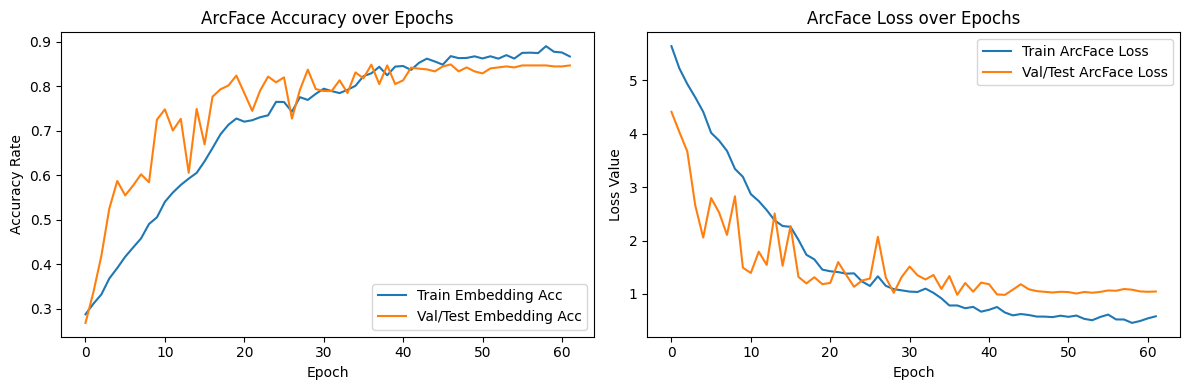

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='Train Embedding Acc')
ax[0].plot(history.history['val_accuracy'], label='Val/Test Embedding Acc')
ax[0].set_title('ArcFace Accuracy over Epochs')
ax[0].set_xlabel('Epoch')
ax[0].set_ylabel('Accuracy Rate')
ax[0].legend()

ax[1].plot(history.history['loss'], label='Train ArcFace Loss')
ax[1].plot(history.history['val_loss'], label='Val/Test ArcFace Loss')
ax[1].set_title('ArcFace Loss over Epochs')
ax[1].set_xlabel('Epoch')
ax[1].set_ylabel('Loss Value')
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluate training, validation, and testing accuracy
train_loss, train_acc = training_model.evaluate(X_train, y_train, verbose=0)
val_loss, val_acc = training_model.evaluate(X_val, y_val, verbose=0)
test_loss, test_acc = training_model.evaluate(X_test, y_test, verbose=0)

print(f"Training Accuracy:   {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Test Accuracy:       {test_acc*100:.2f}%")


Training Accuracy:   99.68%
Validation Accuracy: 84.67%
Test Accuracy:       83.55%


In [ ]:
# Build Per-person Prototype Embeddings
# Generate 128D embeddings for the train and test sets using the trained FaceNet model
print("Generating face embeddings from FaceNet...")
train_embeddings = facenet_model.predict(X_train, verbose=0)
test_embeddings = facenet_model.predict(X_test, verbose=0)

# Convert integer labels back to original string identifiers (e.g., Student/Staff IDs)
train_labels = label_encoder.inverse_transform(y_train)

# Calculate the mean center vector (prototype) for each unique identity
prototype_ids = []
prototype_vecs = []
for person_id in np.unique(train_labels):
    mask = train_labels == person_id

    # Mean position of all training vectors for this person
    proto = train_embeddings[mask].mean(axis=0)

    # Re-normalize back onto the 128D unit hypersphere after averaging
    proto = proto / np.linalg.norm(proto)

    prototype_ids.append(person_id)
    prototype_vecs.append(proto)

prototype_ids = np.array(prototype_ids)
prototype_vecs = np.array(prototype_vecs, dtype=np.float32)

class_prototypes = {
    label_encoder.transform([pid])[0]: vec
    for pid, vec in zip(prototype_ids, prototype_vecs)
}

print("Prototype embeddings built for", len(prototype_ids), "people, dim =", prototype_vecs.shape[1])


Generating face embeddings from FaceNet...
Prototype embeddings built for 35 people, dim = 128


              precision    recall  f1-score   support

        E001       0.79      0.79      0.79        14
        E002       1.00      0.88      0.93         8
        E003       1.00      0.83      0.91        12
        E004       0.82      1.00      0.90         9
        E005       0.85      0.73      0.79        15
        E006       0.92      1.00      0.96        11
        E007       0.91      0.91      0.91        11
        E008       0.79      0.92      0.85        12
        E009       0.86      0.71      0.77        17
        E010       0.82      0.90      0.86        10
        S001       1.00      0.90      0.95        10
        S002       1.00      0.73      0.84        11
        S003       0.81      0.81      0.81        16
        S004       0.75      0.50      0.60         6
        S005       0.93      0.93      0.93        14
        S006       1.00      0.86      0.92        14
        S007       0.50      0.75      0.60         8
        S008       0.89    

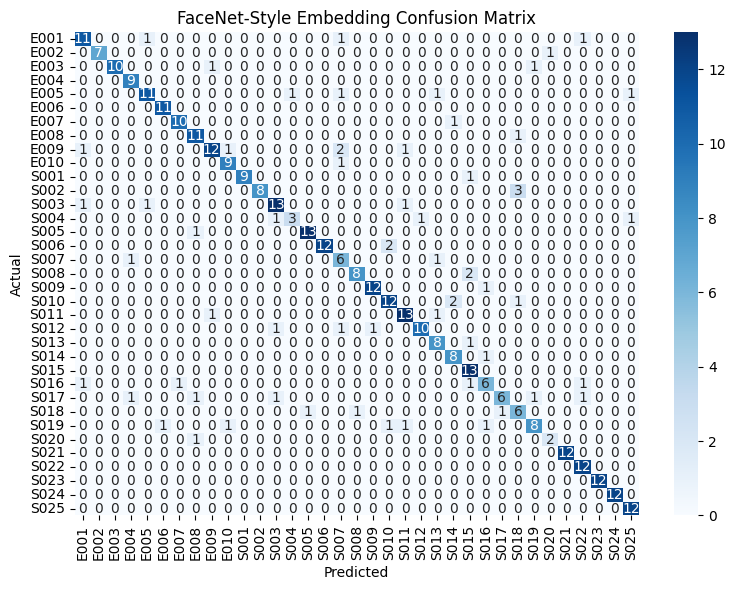

In [ ]:
def predict_face_identity(embedding, prototypes):
    """
    Identifies matching index by measuring cosine similarity.
    """
    best_similarity = -1.0
    predicted_class = -1

    for class_idx, prototype in prototypes.items():
        # Dot product calculates cosine similarity since vectors are already L2 normalized
        similarity = np.dot(embedding, prototype)
        if similarity > best_similarity:
            best_similarity = similarity
            predicted_class = class_idx

    return predicted_class

y_pred = []
for test_emb in test_embeddings:
    y_pred.append(predict_face_identity(test_emb, class_prototypes))

# Evaluate mapping
y_true_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred)

print(classification_report(y_true_labels, y_pred_labels, zero_division=0))

# Display Confusion Matrix
cm = confusion_matrix(y_true_labels, y_pred_labels)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('FaceNet-Style Embedding Confusion Matrix')
plt.tight_layout()
plt.show()

Selected CONFIDENCE_THRESHOLD = 0.490 (maximizes F1 on the validation set, margin ignored at this stage)
  At this threshold -> precision: 0.879, recall: 0.973, F1: 0.924
  ROC AUC (similarity vs. correctness): 0.878


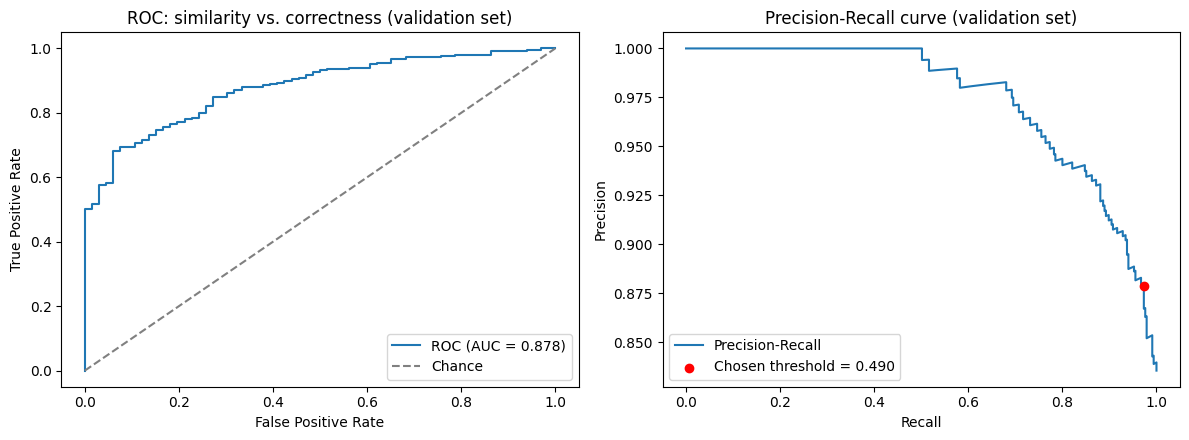

In [ ]:
# =========== Confidence Threshold Selection ===========
from sklearn.metrics import roc_curve, auc, precision_recall_curve

# Vectorized prototype matrix (rows aligned to proto_labels_encoded)
proto_labels_encoded = np.array(sorted(class_prototypes.keys()))
proto_matrix = np.array([class_prototypes[k] for k in proto_labels_encoded], dtype=np.float32)

def best_and_second_sim(embeddings, proto_matrix, proto_labels_encoded):
    """
    Returns (best_sim, second_sim, margin, predicted_encoded_label) for each row.
    """
    sims = embeddings @ proto_matrix.T  # (n_samples, n_classes)
    order = np.argsort(-sims, axis=1)
    best_idx = order[:, 0]
    best_sim = sims[np.arange(len(sims)), best_idx]
    if sims.shape[1] > 1:
        second_idx = order[:, 1]
        second_sim = sims[np.arange(len(sims)), second_idx]
    else:
        second_sim = np.full(len(sims), -1.0)
    margin = best_sim - second_sim
    pred_encoded = proto_labels_encoded[best_idx]
    return best_sim, second_sim, margin, pred_encoded

val_embeddings = facenet_model.predict(X_val, verbose=0)
val_best_sim, _, val_margin, val_pred_encoded = best_and_second_sim(
    val_embeddings, proto_matrix, proto_labels_encoded
)
val_correct = (val_pred_encoded == y_val).astype(int)

# tune CONFIDENCE_THRESHOLD on similarity vs. correctness
fpr, tpr, _ = roc_curve(val_correct, val_best_sim)
roc_auc = auc(fpr, tpr)

precision, recall, pr_thresholds = precision_recall_curve(val_correct, val_best_sim)
f1_scores = np.divide(
    2 * precision * recall, precision + recall,
    out=np.zeros_like(precision), where=(precision + recall) > 0
)
best_idx = np.argmax(f1_scores[:-1]) if len(f1_scores) > 1 else 0
CONFIDENCE_THRESHOLD = float(pr_thresholds[best_idx]) if len(pr_thresholds) > 0 else 0.5

print(f"Selected CONFIDENCE_THRESHOLD = {CONFIDENCE_THRESHOLD:.3f} "
      f"(maximizes F1 on the validation set, margin ignored at this stage)")
print(f"  At this threshold -> precision: {precision[best_idx]:.3f}, "
      f"recall: {recall[best_idx]:.3f}, F1: {f1_scores[best_idx]:.3f}")
print(f"  ROC AUC (similarity vs. correctness): {roc_auc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(fpr, tpr, label=f"ROC (AUC = {roc_auc:.3f})")
ax[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax[0].set_xlabel("False Positive Rate")
ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC: similarity vs. correctness (validation set)")
ax[0].legend(loc="lower right")

ax[1].plot(recall, precision, label="Precision-Recall")
ax[1].scatter(recall[best_idx], precision[best_idx], color="red", zorder=5,
              label=f"Chosen threshold = {CONFIDENCE_THRESHOLD:.3f}")
ax[1].set_xlabel("Recall")
ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curve (validation set)")
ax[1].legend(loc="lower left")
plt.tight_layout()
plt.show()


Selected MARGIN_THRESHOLD = 0.020 (maximizes F1 on the validation set, with CONFIDENCE_THRESHOLD fixed at 0.490)
  Combined rule on validation -> precision: 0.886, recall: 0.970, F1: 0.926


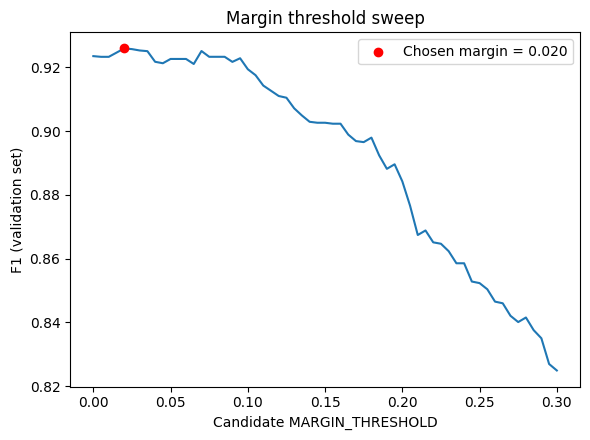

In [ ]:
# tune MARGIN_THRESHOLD with CONFIDENCE_THRESHOLD fixed
margin_candidates = np.linspace(0.0, 0.30, 61)
margin_f1s = []
for m in margin_candidates:
    accept = (val_best_sim >= CONFIDENCE_THRESHOLD) & (val_margin >= m)
    if accept.sum() == 0:
        margin_f1s.append(0.0)
        continue
    p = val_correct[accept].mean()
    r = accept[val_correct == 1].mean() if (val_correct == 1).any() else 0.0
    f1 = 2 * p * r / (p + r) if (p + r) > 0 else 0.0
    margin_f1s.append(f1)

margin_f1s = np.array(margin_f1s)
best_margin_idx = np.argmax(margin_f1s)
MARGIN_THRESHOLD = float(margin_candidates[best_margin_idx])

final_accept = (val_best_sim >= CONFIDENCE_THRESHOLD) & (val_margin >= MARGIN_THRESHOLD)
final_precision = val_correct[final_accept].mean() if final_accept.any() else 0.0
final_recall = final_accept[val_correct == 1].mean() if (val_correct == 1).any() else 0.0

print(f"Selected MARGIN_THRESHOLD = {MARGIN_THRESHOLD:.3f} "
      f"(maximizes F1 on the validation set, with CONFIDENCE_THRESHOLD fixed at "
      f"{CONFIDENCE_THRESHOLD:.3f})")
print(f"  Combined rule on validation -> precision: {final_precision:.3f}, "
      f"recall: {final_recall:.3f}, F1: {margin_f1s[best_margin_idx]:.3f}")

plt.figure(figsize=(6, 4.5))
plt.plot(margin_candidates, margin_f1s)
plt.scatter([MARGIN_THRESHOLD], [margin_f1s[best_margin_idx]], color="red", zorder=5,
            label=f"Chosen margin = {MARGIN_THRESHOLD:.3f}")
plt.xlabel("Candidate MARGIN_THRESHOLD")
plt.ylabel("F1 (validation set)")
plt.title("Margin threshold sweep")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
# =========== Evaluates the chosen threshold on the test set ===========
test_best_sim, _, test_margin, test_pred_encoded = best_and_second_sim(
    test_embeddings, proto_matrix, proto_labels_encoded
)
test_correct = (test_pred_encoded == y_test)
accepted = (test_best_sim >= CONFIDENCE_THRESHOLD) & (test_margin >= MARGIN_THRESHOLD)
n_accepted = accepted.sum()

print(f"Test predictions accepted (similarity >= {CONFIDENCE_THRESHOLD:.3f} AND "
      f"margin >= {MARGIN_THRESHOLD:.3f}): {n_accepted}/{len(y_test)} "
      f"({100*n_accepted/len(y_test):.1f}%)")
if n_accepted > 0:
    print(f"Accuracy among accepted predictions:  {100*test_correct[accepted].mean():.2f}%")
n_rejected_but_correct = np.sum((~accepted) & test_correct)
print(f"Correct predictions rejected by the thresholds: {n_rejected_but_correct} "
      f"(would have been right, but similarity/margin fell below the cutoffs)")


Test predictions accepted (similarity >= 0.490 AND margin >= 0.020): 364/401 (90.8%)
Accuracy among accepted predictions:  89.56%
Correct predictions rejected by the thresholds: 11 (would have been right, but similarity/margin fell below the cutoffs)


In [ ]:
# Save models
save_dir = "/content/drive/MyDrive/Colab Notebooks/Dataset/models2/"
os.makedirs(save_dir, exist_ok=True)

embedding_model_path = os.path.join(save_dir, "face_embedding_model.keras")
facenet_model.save(embedding_model_path)

np.save(os.path.join(save_dir, "label_classes.npy"), label_encoder.classes_)
joblib.dump(label_encoder, os.path.join(save_dir, "label_encoder.pkl"))

np.save(os.path.join(save_dir, "prototype_ids.npy"), prototype_ids)
np.save(os.path.join(save_dir, "prototype_vecs.npy"), prototype_vecs)

np.save(os.path.join(save_dir, "confidence_threshold.npy"), CONFIDENCE_THRESHOLD)
np.save(os.path.join(save_dir, "margin_threshold.npy"), MARGIN_THRESHOLD)
print("Saved all files to Drive.")

Saved FaceNet embedding model, label encoder, and prototypes to Drive.
